In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [2]:
# 1. Read WhatsApp chat file
with open("Mentor.txt.txt", "r", encoding="utf-8") as file:
    chat_text = file.read()

In [3]:
# 2. Extract Date, Time, Sender, and Message
pattern = r'^\[(.*?), (.*?)\] (.*?): (.*)$'

messages = []
current = None

for line in chat_text.splitlines():
    match = re.match(pattern, line)

    if match:
        if current:
            messages.append(current)

        current = {
            "Date": match.group(1),
            "Time": match.group(2),
            "Sender": match.group(3),
            "Message": match.group(4)
        }

    elif current:
        current["Message"] += "\n" + line

if current:
    messages.append(current)

In [4]:
# 3. Convert into a DataFrame
chat_df = pd.DataFrame(messages)

In [5]:
# 4. Basic preprocessing
chat_df["Message"] = chat_df["Message"].str.strip()

In [6]:
# Remove empty messages
chat_df = chat_df[chat_df["Message"] != ""]

In [7]:
# Remove messages containing only media placeholders
media_pattern = (
    r"<(image|video|audio|voice message|sticker|gif|document) omitted>"
)

chat_df = chat_df[
    ~chat_df["Message"].str.fullmatch(media_pattern, case=False)
].copy()

In [8]:
# 5. Display the cleaned table
display(chat_df[["Date", "Time", "Sender", "Message"]])

,Date,Time,Sender,Message
0,11/10/25,6:50:16 AM,Logeshwarai Tutor Hope Ai Coimbatore,"Hi LOKESHWARAN R,\n\nI hope your learning jour..."
1,11/10/25,8:47:00 AM,You,"“Yes ma’am, I’m currently watching videos abou..."
2,11/10/25,10:11:20 AM,Logeshwarai Tutor Hope Ai Coimbatore,Okay Sir
3,11/11/25,11:27:00 AM,Logeshwarai Tutor Hope Ai Coimbatore,Hi
5,11/11/25,11:27:40 AM,Logeshwarai Tutor Hope Ai Coimbatore,.ipynb
...,...,...,...,...
1527,10/12/26,8:03:27 AM,You,https://github.com/LokeshDataScienceAI/Week-13...
1528,10/12/26,8:04:04 AM,You,In this link for TF-IDF
1529,10/12/26,8:04:17 AM,You,https://github.com/LokeshDataScienceAI/Week-13...
1530,10/12/26,8:04:57 AM,You,In this link for Hashing vectorizer


In [9]:
# 6. Save CSV and Excel files
base_name = "My mentor conversation chat preprocessing"

chat_df.to_csv(
    base_name + ".csv",
    index=False,
    encoding="utf-8-sig"
)

chat_df.to_excel(
    base_name + ".xlsx",
    index=False
)

In [10]:
# Combine all WhatsApp messages into one text
text = " ".join(chat_df["Message"].dropna().astype(str))

In [11]:
# Add common words to ignore
stopwords = set(STOPWORDS)
stopwords.update([
    "sir", "maam", "mam", "madam",
    "yes", "ok", "okay", "hi", "hello",
    "thank", "thanks", "please"
])

In [12]:
# Generate Word Cloud
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="white",
    stopwords=stopwords,
    collocations=False
).generate(text)

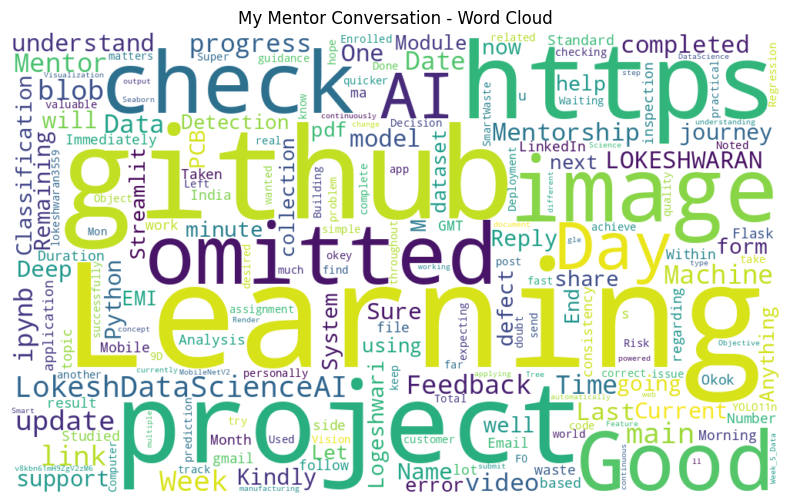

In [13]:
# Display Word Cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("My Mentor Conversation - Word Cloud")
plt.show()